# ESOL 数据探索

读取原始数据、报告质量检查并展示分布与相关性。全部数据保留，不在此训练模型。

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdkit import Chem

# 从项目根目录或 notebooks 目录启动都能找到数据，不依赖本机绝对路径。
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "delaney-processed.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("请从项目根目录或 notebooks 目录启动。")
data_path = project_root / "data" / "delaney-processed.csv"
df = pd.read_csv(data_path)
target = "measured log solubility in mols per litre"
required = ["Compound ID", "smiles", target]
if not set(required).issubset(df.columns) or df[required].isna().any().any():
    raise ValueError("必要列缺失或含缺失值；停止运行，不自动删除数据。")
if not np.isfinite(df[target].to_numpy(dtype=float)).all():
    raise ValueError("目标值包含非有限数值。")
molecules = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
invalid_rows = [i for i, mol in enumerate(molecules)
                if mol is None or mol.GetNumAtoms() == 0]
if invalid_rows:
    raise ValueError(f"无法构建分子的行号：{invalid_rows}")
canonical_smiles = [Chem.MolToSmiles(mol) for mol in molecules]
print("Data shape:", df.shape)
print("SHA256:", hashlib.sha256(data_path.read_bytes()).hexdigest())
print("Duplicate rows:", int(df.duplicated().sum()))
print("Repeated canonical structures:", int(pd.Series(canonical_smiles).duplicated().sum()))
# 重复结构仅报告，保留原始行顺序和既有数据划分。

Data shape: (1128, 10)
SHA256: 3fa1b501b2f940d4b016c3798f5fcd4c897b8455a0217efbb3715ac35011f290
Duplicate rows: 0
Repeated canonical structures: 11


## 描述统计

目标是 logS = log10(S / (mol L⁻¹))。分子量单位 g mol⁻¹，极性表面积单位 Å²。

In [2]:
cols = [
    "Molecular Weight",
    "Number of H-Bond Donors",
    "Number of Rings",
    "Number of Rotatable Bonds",
    "Polar Surface Area",
    "measured log solubility in mols per litre"
]

display(df[cols].head())

df[cols].describe()

,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
0,457.432,7,3,7,202.32,-0.77
1,201.225,1,2,2,42.24,-3.30
2,152.237,0,0,4,17.07,-2.06
3,278.354,0,5,0,0.00,-7.87
4,84.143,0,1,0,0.00,-1.33


,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


In [3]:
target = "measured log solubility in mols per litre"

print(df[target].describe())

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: measured log solubility in mols per litre, dtype: float64


## 目标分布

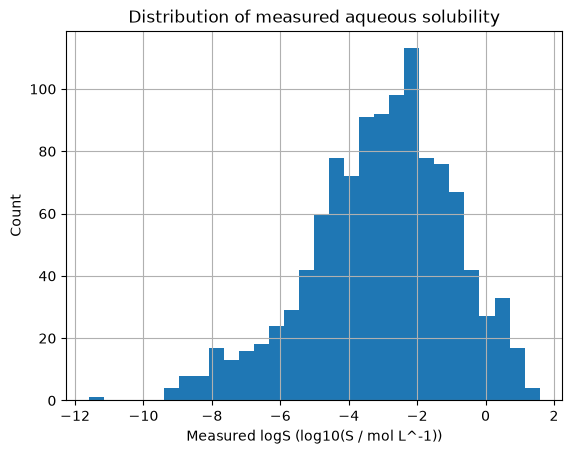

In [4]:
import matplotlib.pyplot as plt

df[target].hist(bins=30)

plt.xlabel("Measured logS (log10(S / mol L^-1))")
plt.ylabel("Count")
plt.title("Distribution of measured aqueous solubility")
plt.show()

## 分子量与溶解度

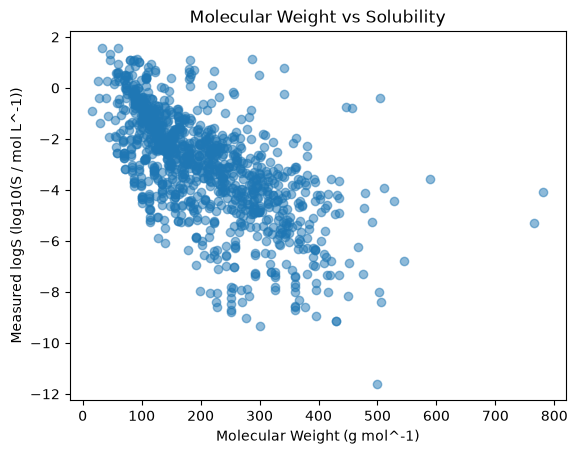

In [5]:
plt.scatter(
    df["Molecular Weight"],
    df[target],
    alpha=0.5
)

plt.xlabel("Molecular Weight (g mol^-1)")
plt.ylabel("Measured logS (log10(S / mol L^-1))")
plt.title("Molecular Weight vs Solubility")
plt.show()

## 极性表面积与溶解度

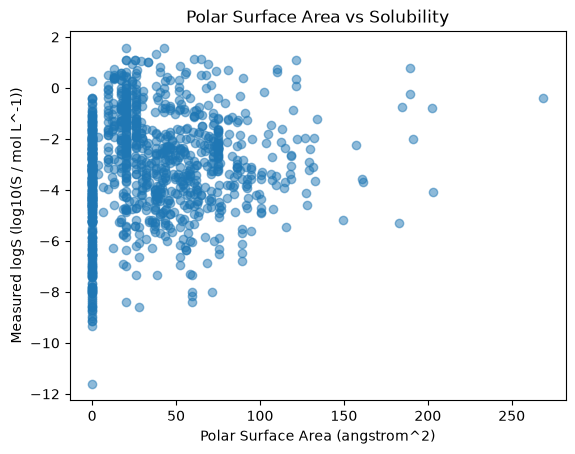

In [6]:
plt.scatter(
    df["Polar Surface Area"],
    df[target],
    alpha=0.5
)

plt.xlabel("Polar Surface Area (angstrom^2)")
plt.ylabel("Measured logS (log10(S / mol L^-1))")
plt.title("Polar Surface Area vs Solubility")
plt.show()

## Pearson 相关性

相关性描述本数据集的线性关系，不代表因果关系。

In [7]:
features = ["Molecular Weight", "Polar Surface Area", "Number of H-Bond Donors", "Number of Rings", "Number of Rotatable Bonds"]
selected = features + [target]

corr_matrix = df[selected].corr()

print(corr_matrix)

                                           Molecular Weight  \
Molecular Weight                                   1.000000   
Polar Surface Area                                 0.475440   
Number of H-Bond Donors                            0.254877   
Number of Rings                                    0.652521   
Number of Rotatable Bonds                          0.396894   
measured log solubility in mols per litre         -0.640189   

                                           Polar Surface Area  \
Molecular Weight                                     0.475440   
Polar Surface Area                                   1.000000   
Number of H-Bond Donors                              0.755932   
Number of Rings                                      0.308606   
Number of Rotatable Bonds                            0.286723   
measured log solubility in mols per litre            0.123210   

                                           Number of H-Bond Donors  \
Molecular Weight                

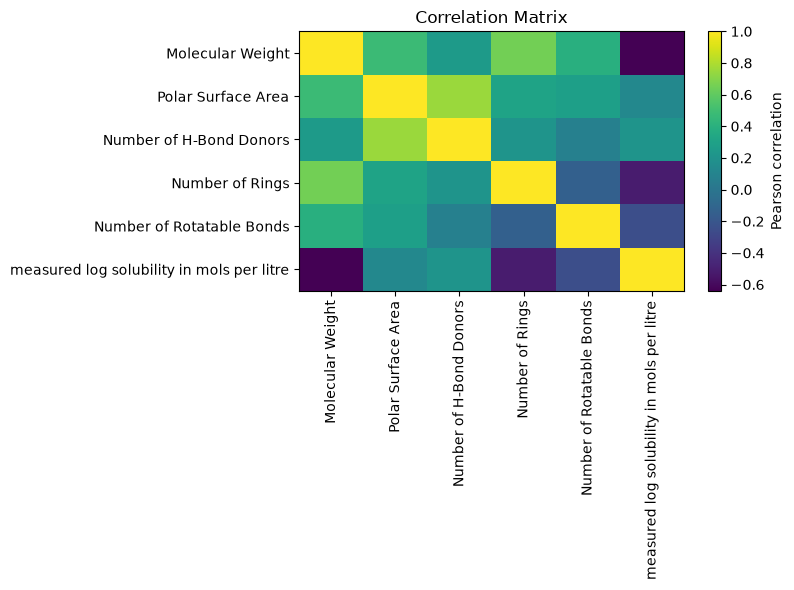

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Pearson correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.index)),
    corr_matrix.index
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

## 数据中已有的 ESOL 预测

仅用作探索，不作为后续训练的输入，也不是独立测试集成绩。

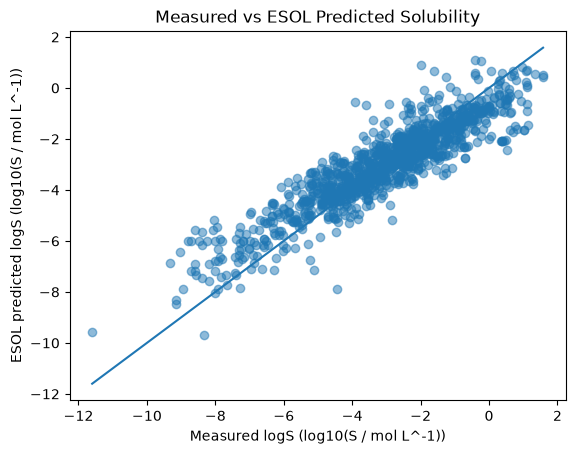

In [9]:
predicted = "ESOL predicted log solubility in mols per litre"


min_val = min(df[target].min(), df[predicted].min())
max_val = max(df[target].max(), df[predicted].max())

plt.scatter(
    df[target],
    df[predicted],
    alpha=0.5
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Measured logS (log10(S / mol L^-1))")
plt.ylabel("ESOL predicted logS (log10(S / mol L^-1))")
plt.title("Measured vs ESOL Predicted Solubility")

plt.show()

In [10]:
df["error"] = (
    df["ESOL predicted log solubility in mols per litre"]
    - df["measured log solubility in mols per litre"]
)

df["abs_error"] = df["error"].abs()

df.sort_values("abs_error", ascending=False).head(10)

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles,error,abs_error
939,bromadiolone,-7.877,1,527.414,2,5,6,70.67,-4.445,OC(CC(c1ccccc1)c3c(O)c2ccccc2oc3=O)c4ccc(cc4)c...,-3.432,3.432
852,uric acid,-0.541,1,168.112,4,2,0,114.37,-3.930,O=c2[nH]c(=O)c1[nH]c(=O)[nH]c1[nH]2,3.389,3.389
819,Napthacene,-5.568,2,228.294,0,4,0,0.00,-8.600,c1ccc2cc3cc4ccccc4cc3cc2c1,3.032,3.032
292,Dimecron,-2.426,1,299.691,0,0,8,65.07,0.523,CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl,-2.949,2.949
918,guanine,-0.670,1,151.129,3,2,0,100.45,-3.583,Nc2nc1[nH]cnc1c(=O)[nH]2,2.913,2.913
733,alloxantin,0.919,1,286.156,6,2,1,191.00,-1.990,C1(=O)NC(=O)NC(=O)C1(O)C2(O)C(=O)NC(=O)NC2(=O),2.909,2.909
845,Benzo(b)fluorene,-5.189,2,216.283,0,4,0,0.00,-8.040,C1c2ccccc2c3cc4ccccc4cc13,2.851,2.851
220,Perylene,-6.007,2,252.316,0,5,0,0.00,-8.804,c1cc2cccc3c4cccc5cccc(c(c1)c23)c54,2.797,2.797
788,1-Octadecanol,-5.649,1,270.501,1,0,16,20.23,-8.400,CCCCCCCCCCCCCCCCCCO,2.751,2.751
637,Benzo(a)pyrene,-6.007,2,252.316,0,5,0,0.00,-8.699,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45,2.692,2.692
